# COMP 472 · Neural Network

**Fall 2026 · Kaggle Project**

This notebook trains a feed-forward neural network with PyTorch on both datasets:

* image recognition: 500 input features, 50 classes
* sentiment analysis: 768 input features, 3 classes

It tests several hyperparameters on a validation split, analyses the errors, compares the network with the k-NN and Decision Tree results, and writes the Kaggle submission.

**Sections:** 1 Setup · 2 Data · 3 Model and training · 4 Sentiment experiments · 5 Image experiments · 6 Error analysis · 7 Comparison and final choice · 8 Kaggle submission

## 1 · Setup

We fix the random seeds so that the results can be reproduced. We print the Python and library versions for the same reason.

Put the five Kaggle CSV files in the same folder as this notebook. A CPU is enough to run it; a GPU is not needed.

In [1]:
import copy
import platform
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import torch.nn as nn
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Python      ", platform.python_version())
print("NumPy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("PyTorch     ", torch.__version__)

Python       3.12.3
NumPy        2.5.5
pandas       3.1.1
scikit-learn 1.9.1
PyTorch      2.15.0+cpu


## 2 · Data

We use the same split as the k-NN and Decision Tree notebooks: 80% training and 20% validation, stratified by label, with `random_state=42`. All models are therefore compared on the same validation examples. The test files are only used in section 8.

In [2]:
image_train = pd.read_csv("image_train.csv")
sentiment_train = pd.read_csv("sentiment_train.csv")

X_image = image_train.drop(columns=["id", "label"]).to_numpy(np.float32)
y_image = image_train["label"].to_numpy(np.int64)
X_sentiment = sentiment_train.drop(columns=["id", "label"]).to_numpy(np.float32)
y_sentiment = sentiment_train["label"].to_numpy(np.int64)

X_img_train, X_img_val, y_img_train, y_img_val = train_test_split(
    X_image, y_image, test_size=0.2, random_state=42, stratify=y_image)
X_sent_train, X_sent_val, y_sent_train, y_sent_val = train_test_split(
    X_sentiment, y_sentiment, test_size=0.2, random_state=42, stratify=y_sentiment)

print("Image:     train", X_img_train.shape, " validation", X_img_val.shape)
print("Sentiment: train", X_sent_train.shape, " validation", X_sent_val.shape)

Image:     train (16000, 500)  validation (4000, 500)
Sentiment: train (9600, 768)  validation (2400, 768)


### Standardization

We transform each feature so that it has a mean of 0 and a standard deviation of 1. Neural networks train more reliably when all inputs have a similar range.

The mean and standard deviation are computed on the **training split only**. The same values are then applied to the validation data. This avoids data leakage: no information from the validation data is used during training.

In [3]:
def fit_standardizer(X_train):
    mean = X_train.mean(axis=0)
    std = X_train.std(axis=0)
    std[std < 1e-8] = 1.0          # avoid dividing by zero
    return lambda X: ((X - mean) / std).astype(np.float32)

scale_img = fit_standardizer(X_img_train)
scale_sent = fit_standardizer(X_sent_train)

DATA = {
    "image":     (scale_img(X_img_train), y_img_train, scale_img(X_img_val), y_img_val),
    "sentiment": (scale_sent(X_sent_train), y_sent_train, scale_sent(X_sent_val), y_sent_val),
}
N_CLASSES = {"image": 50, "sentiment": 3}

## 3 · Model and training

### Network

The network is a sequence of fully connected layers (`nn.Linear`). Each hidden layer is followed by an activation function (ReLU by default). Dropout can be added after each hidden layer.

* The last layer has one output per class: 50 for images and 3 for sentiment.
* There is no softmax layer at the end, because `nn.CrossEntropyLoss` applies softmax itself.
* **Dropout** sets a random fraction of the hidden-layer outputs to 0 at each training step. It is only active during training.
* **Input dropout** applies dropout to the input features. It is only used in the image experiments.

In [4]:
ACTIVATIONS = {"relu": nn.ReLU, "tanh": nn.Tanh}

def build_network(n_inputs, hidden_sizes, n_classes, activation="relu", dropout=0.0, input_dropout=0.0):
    layers = []
    if input_dropout > 0:
        layers.append(nn.Dropout(input_dropout))
    previous = n_inputs
    for size in hidden_sizes:
        layers.append(nn.Linear(previous, size))
        layers.append(ACTIVATIONS[activation]())
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        previous = size
    layers.append(nn.Linear(previous, n_classes))
    return nn.Sequential(*layers)

print(build_network(768, [256, 64], 3))

Sequential(
  (0): Linear(in_features=768, out_features=256, bias=True)
  (1): ReLU()
  (2): Linear(in_features=256, out_features=64, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=3, bias=True)
)


### Training

Training follows the PyTorch loop from Lab 7:

1. Shuffle the training data and split it into mini-batches.
2. For each mini-batch: compute the outputs, compute the cross-entropy loss, compute the gradients with `loss.backward()`, and update the weights with the Adam optimizer (`optimizer.step()`). `weight_decay` adds an L2 penalty on the weights.
3. After each epoch, measure the loss and the accuracy on the training and validation sets.
4. **Early stopping:** keep the weights from the epoch with the highest validation accuracy. Stop when validation accuracy has not improved for `patience` epochs. Without early stopping, the network can keep improving on the training data while getting worse on the validation data.

In [5]:
def to_tensor(X):
    return torch.tensor(np.asarray(X), dtype=torch.float32)

def predict_proba(model, X):
    model.eval()                                   # dropout off
    with torch.no_grad():
        return torch.softmax(model(to_tensor(X)), dim=1).numpy()

def evaluate(model, X, y):
    probs = predict_proba(model, X)
    loss = -np.mean(np.log(probs[np.arange(len(y)), y] + 1e-12))
    acc = np.mean(probs.argmax(axis=1) == y)
    return float(loss), float(acc)

def train_model(model, X_train, y_train, X_val=None, y_val=None, *, lr=1e-3, weight_decay=0.0,
                batch_size=128, epochs=100, patience=10, seed=SEED):
    torch.manual_seed(seed)
    dataset = TensorDataset(to_tensor(X_train), torch.tensor(y_train, dtype=torch.long))
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.CrossEntropyLoss()

    history = {"loss": [], "acc": [], "val_loss": [], "val_acc": []}
    best_acc, best_state, best_epoch, waited = -1.0, None, epochs, 0
    start = time.time()

    for epoch in range(1, epochs + 1):
        model.train()                              # dropout on
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)          # forward pass and loss
            loss.backward()                        # gradients
            optimizer.step()                       # weight update

        train_loss, train_acc = evaluate(model, X_train, y_train)
        history["loss"].append(train_loss)
        history["acc"].append(train_acc)
        if X_val is None:                          # final training: fixed number of epochs
            continue

        val_loss, val_acc = evaluate(model, X_val, y_val)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        if val_acc > best_acc:
            best_acc, best_epoch, waited = val_acc, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            waited += 1
            if waited >= patience:
                break

    if best_state is not None:
        model.load_state_dict(best_state)          # weights from the best epoch
    history["best_epoch"] = best_epoch
    history["time"] = time.time() - start
    return history

`run_experiment` builds and trains one network and adds one row to the results table. `plot_history` draws the training and validation curves. The dashed line marks the epoch kept by early stopping.

In [6]:
results = []

def run_experiment(task, experiment, setting, hidden_sizes, *, activation="relu", dropout=0.0,
                   input_dropout=0.0, **train_args):
    X_tr, y_tr, X_va, y_va = DATA[task]
    torch.manual_seed(SEED)
    model = build_network(X_tr.shape[1], hidden_sizes, N_CLASSES[task], activation, dropout, input_dropout)
    history = train_model(model, X_tr, y_tr, X_va, y_va, **train_args)
    row = {"Task": task, "Experiment": experiment, "Setting": setting,
           "Train acc (%)": round(100 * evaluate(model, X_tr, y_tr)[1], 2),
           "Val acc (%)": round(100 * evaluate(model, X_va, y_va)[1], 2),
           "Best epoch": history["best_epoch"], "Time (s)": round(history["time"], 1)}
    results.append(row)
    print(f"{setting:34s} train {row['Train acc (%)']:6.2f}%   val {row['Val acc (%)']:6.2f}%   "
          f"best epoch {row['Best epoch']:3d}   {row['Time (s)']:5.1f}s")
    return model, history

def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    epochs = range(1, len(history["loss"]) + 1)
    for ax, key, name in [(axes[0], "loss", "loss"), (axes[1], "acc", "accuracy")]:
        ax.plot(epochs, history[key], label="training")
        ax.plot(epochs, history["val_" + key], label="validation")
        ax.axvline(history["best_epoch"], color="gray", linestyle="--", linewidth=1, label="kept epoch")
        ax.set_xlabel("epoch"); ax.set_ylabel(name); ax.grid(alpha=0.25); ax.legend(frameon=False)
    fig.suptitle(title); plt.tight_layout(); plt.show()

## 4 · Sentiment experiments

We start from the network given as an example in the project description: **768 → 256 → 64 → 3**. We train it with Adam, a learning rate of 0.001 and mini-batches of 128. We then change **one hyperparameter at a time** and keep the others fixed. This way, each change in accuracy comes from one hyperparameter only.

### 4.1 Baseline

768-256-64-3                       train  71.73%   val  65.79%   best epoch   1     1.9s


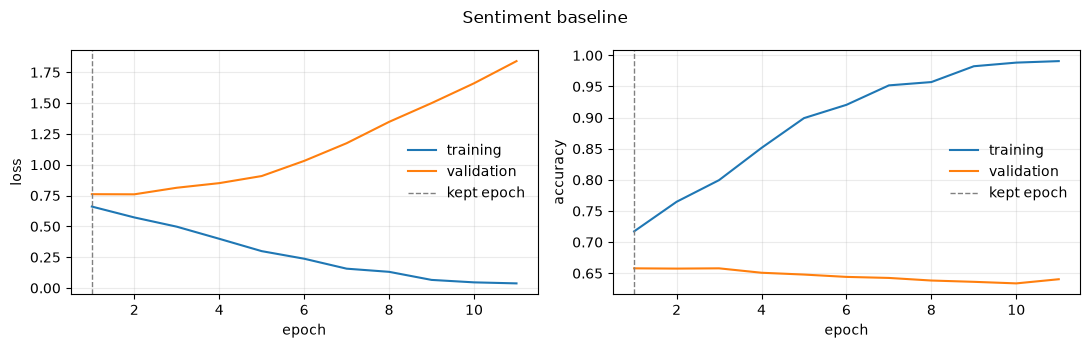

In [7]:
SENT_BASE = dict(hidden_sizes=[256, 64], lr=1e-3, batch_size=128, epochs=100, patience=10)

_, sent_base_history = run_experiment("sentiment", "baseline", "768-256-64-3", **SENT_BASE)
plot_history(sent_base_history, "Sentiment baseline")

**Observation.** The best validation accuracy (65.79%) is reached after the first epoch. After that, training accuracy keeps rising (to almost 100%), but validation accuracy falls. Training loss goes down while validation loss goes up. This is **overfitting**: the network keeps improving on the training examples but gets worse on new examples. Early stopping keeps the weights from epoch 1.

### 4.2 Learning rate

We test the values suggested in the project description.

In [8]:
for lr in [1e-2, 1e-3, 1e-4]:
    run_experiment("sentiment", "learning rate", f"lr = {lr}", **{**SENT_BASE, "lr": lr})

lr = 0.01                          train  81.97%   val  64.04%   best epoch   7     3.1s


lr = 0.001                         train  71.73%   val  65.79%   best epoch   1     1.9s


lr = 0.0001                        train  84.97%   val  67.46%   best epoch  12     3.9s


### 4.3 Number and size of hidden layers

`[]` means no hidden layer. Without a hidden layer, the network is a linear classifier (softmax regression). This lets us check whether the hidden layers add anything.

In [9]:
for hidden in [[], [64], [256, 64], [1024, 512]]:
    run_experiment("sentiment", "hidden layers", f"hidden = {hidden}", **{**SENT_BASE, "hidden_sizes": hidden})

hidden = []                        train  72.03%   val  66.71%   best epoch  10     1.6s


hidden = [64]                      train  70.83%   val  65.88%   best epoch   1     1.5s


hidden = [256, 64]                 train  71.73%   val  65.79%   best epoch   1     2.5s


hidden = [1024, 512]               train  81.29%   val  65.75%   best epoch   3    10.2s


### 4.4 Activation function

In [10]:
for activation in ["relu", "tanh"]:
    run_experiment("sentiment", "activation", activation, activation=activation, **SENT_BASE)

relu                               train  71.73%   val  65.79%   best epoch   1     2.3s


tanh                               train  72.18%   val  65.88%   best epoch   2     2.6s


### 4.5 Dropout and weight decay

Both are used to reduce overfitting.

In [11]:
for dropout in [0.0, 0.2, 0.5]:
    run_experiment("sentiment", "dropout", f"dropout = {dropout}", dropout=dropout, **SENT_BASE)
for weight_decay in [0.0, 1e-4, 1e-3]:
    run_experiment("sentiment", "weight decay", f"weight_decay = {weight_decay}", **{**SENT_BASE, "weight_decay": weight_decay})

dropout = 0.0                      train  71.73%   val  65.79%   best epoch   1     2.6s


dropout = 0.2                      train  82.02%   val  66.54%   best epoch   4     4.1s


dropout = 0.5                      train  90.34%   val  66.88%   best epoch  19     9.1s


weight_decay = 0.0                 train  71.73%   val  65.79%   best epoch   1     3.5s


weight_decay = 0.0001              train  76.25%   val  66.12%   best epoch   2     3.3s


weight_decay = 0.001               train  78.94%   val  66.17%   best epoch   3     3.2s


### 4.6 Batch size

In [12]:
for batch_size in [32, 128, 512]:
    run_experiment("sentiment", "batch size", f"batch size = {batch_size}", **{**SENT_BASE, "batch_size": batch_size})

batch size = 32                    train  80.83%   val  66.12%   best epoch   3     6.0s


batch size = 128                   train  71.73%   val  65.79%   best epoch   1     2.6s


batch size = 512                   train  80.40%   val  66.96%   best epoch   4     2.4s


### 4.7 Results and final configuration

The table summarizes sections 4.2 to 4.6. The baseline (learning rate 0.001, batch size 128, no dropout, no weight decay) has a validation accuracy of 65.79%.

| Hyperparameter | Values tested | Best value | Validation accuracy |
|:--|:--|:--|--:|
| Learning rate | 0.01, 0.001, 0.0001 | 0.0001 | 67.46% |
| Hidden layers | none, [64], [256, 64], [1024, 512] | none | 66.71% |
| Activation | ReLU, tanh | tanh | 65.88% |
| Dropout | 0, 0.2, 0.5 | 0.5 | 66.88% |
| Weight decay | 0, 0.0001, 0.001 | 0.001 | 66.17% |
| Batch size | 32, 128, 512 | 512 | 66.96% |

What the results show:

* With the baseline settings, the network overfits after 1 to 3 epochs. Every setting that improved validation accuracy either makes each weight update smaller (smaller learning rate, larger batch) or reduces overfitting (dropout, weight decay). With these settings, the best epoch comes later.
* The model with **no hidden layer** (a linear classifier) scored 66.71%. This is higher than every network with hidden layers at the baseline settings (65.75% to 65.88%). So, for these BERT features, a linear classifier already does about as well as an untuned network with hidden layers.
* The networks with hidden layers differ by at most 0.13%, and ReLU and tanh differ by 0.09%. One validation example is worth about 0.04%, so these differences are only 2 to 3 examples and are too small to matter.

**Final configuration.** We combine the best value from each experiment: learning rate 0.0001, dropout 0.5, weight decay 0.001 and batch size 512. We keep two hidden layers (256 and 64) and ReLU. The project asks for a network with hidden layers, and the differences between layer sizes and between activations were very small. A smaller learning rate needs more epochs, so we allow up to 300 epochs with a patience of 15.

final configuration                train  85.29%   val  68.00%   best epoch  58    18.1s


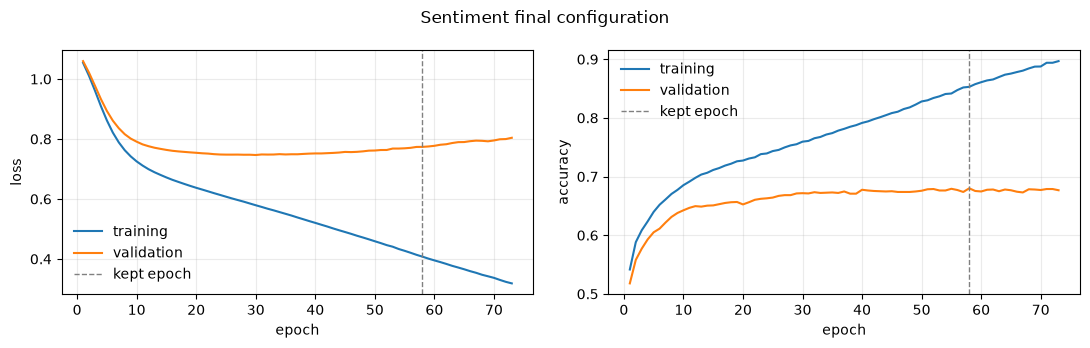

In [13]:
SENT_FINAL = dict(hidden_sizes=[256, 64], dropout=0.5, weight_decay=1e-3, lr=1e-4, batch_size=512, epochs=300, patience=15)

sent_model, sent_final_history = run_experiment("sentiment", "final", "final configuration", **SENT_FINAL)
plot_history(sent_final_history, "Sentiment final configuration")

**Observation.** The final configuration reaches **68.00%** validation accuracy at epoch 58. The baseline reached 65.79% at epoch 1. Validation accuracy now increases slowly over many epochs instead of peaking after the first one. Training accuracy (85.29%) is still higher than validation accuracy, so some overfitting remains.

The final network is 1.29 points better than the linear model from 4.3. The linear model was only tested with the baseline settings, so this comparison is approximate. The hidden layers give a small improvement for this task.

## 5 · Image experiments

Each image run takes longer than a sentiment run, so we run fewer experiments. We start from the same example network: **500 → 256 → 64 → 50**.

### 5.1 Baseline

500-256-64-50                      train 100.00%   val  33.48%   best epoch  14     8.7s


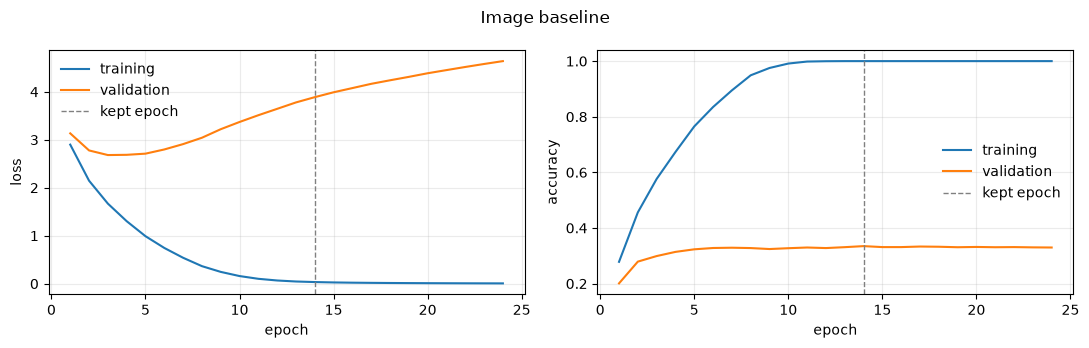

In [14]:
IMG_BASE = dict(hidden_sizes=[256, 64], lr=1e-3, batch_size=128, epochs=60, patience=10)

_, img_base_history = run_experiment("image", "baseline", "500-256-64-50", **IMG_BASE)
plot_history(img_base_history, "Image baseline")

**Observation.** Training accuracy reaches 100%, but validation accuracy stays around 33%. Validation loss is lowest at epoch 3 and then rises, while training loss drops to almost 0. This is **strong overfitting**: the network fits every training image but does not perform well on new images.

### 5.2 Larger hidden layers

In [15]:
run_experiment("image", "hidden layers", "hidden = [1024, 512]", **{**IMG_BASE, "hidden_sizes": [1024, 512]});

hidden = [1024, 512]               train 100.00%   val  38.22%   best epoch  10    28.5s


### 5.3 Dropout

We add dropout 0.3 after each hidden layer and input dropout 0.5. Input dropout sets half of the 500 input features to 0 at random at each training step, so the network does not see exactly the same input twice.

[1024, 512] + dropout 0.3 + input dropout 0.5 train  96.76%   val  44.00%   best epoch  60   127.2s


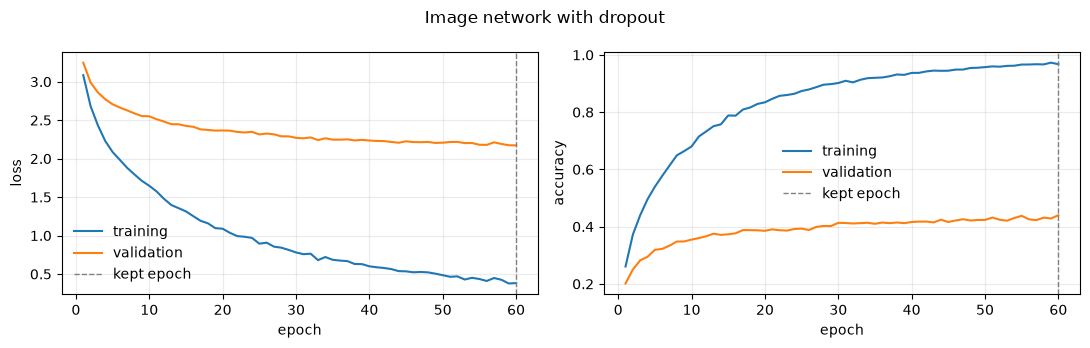

In [16]:
IMG_FINAL = dict(hidden_sizes=[1024, 512], dropout=0.3, input_dropout=0.5, lr=1e-3, batch_size=128, epochs=60, patience=10)

img_model, img_final_history = run_experiment("image", "dropout", "[1024, 512] + dropout 0.3 + input dropout 0.5", **IMG_FINAL)
plot_history(img_final_history, "Image network with dropout")

**Observation.**

| Network | Train accuracy | Validation accuracy |
|:--|--:|--:|
| 256 → 64 | 100.00% | 33.48% |
| 1024 → 512 | 100.00% | 38.22% |
| 1024 → 512 with dropout | 96.76% | 44.00% |

Larger hidden layers improve validation accuracy by about 5 points. Dropout improves it by about 6 more points and lowers training accuracy, so dropout reduces overfitting. The best epoch is the last one (60), so more epochs might improve the result a little.

The best network (44.00%) is still below k-NN with k = 1 (53.08% in `KNN.ipynb`). The gap between training and validation accuracy shows that the network still overfits. The network has about 1.06 million weights (500 × 1024 + 1024 × 512 + 512 × 50, plus the biases), and it is trained on 16,000 images (320 per class). With this many weights, it can fit all the training images exactly, which is what happens without dropout.

## 6 · Error analysis

### 6.1 Sentiment: performance per class

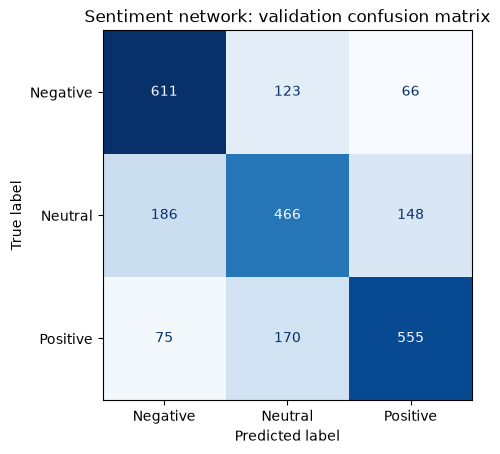

              precision    recall  f1-score   support

    Negative      0.701     0.764     0.731       800
     Neutral      0.614     0.583     0.598       800
    Positive      0.722     0.694     0.707       800

    accuracy                          0.680      2400
   macro avg      0.679     0.680     0.679      2400
weighted avg      0.679     0.680     0.679      2400



In [17]:
SENT_NAMES = ["Negative", "Neutral", "Positive"]
X_sv, y_sv = DATA["sentiment"][2], DATA["sentiment"][3]
sent_val_pred = predict_proba(sent_model, X_sv).argmax(axis=1)

ConfusionMatrixDisplay(confusion_matrix(y_sv, sent_val_pred), display_labels=SENT_NAMES).plot(cmap="Blues", colorbar=False)
plt.title("Sentiment network: validation confusion matrix"); plt.show()
print(classification_report(y_sv, sent_val_pred, target_names=SENT_NAMES, digits=3))

**Is the neutral class harder than negative or positive? Yes.** Neutral has the lowest precision (0.614), recall (0.583) and F1-score (0.598). The confusion matrix shows that neutral tweets are misclassified in both directions: 186 as negative and 148 as positive. Out of 768 mistakes, 627 (82%) involve the neutral class. Only 141 mistakes are between negative and positive. Negative has the highest recall (0.764).

### 6.2 Image: most frequently confused classes

In [18]:
X_iv, y_iv = DATA["image"][2], DATA["image"][3]
img_val_pred = predict_proba(img_model, X_iv).argmax(axis=1)
cm = confusion_matrix(y_iv, img_val_pred, labels=range(50))
np.fill_diagonal(cm, 0)                    # keep only the mistakes

pairs = sorted(((cm[i, j], i, j) for i in range(50) for j in range(50) if cm[i, j] > 0), reverse=True)[:10]
display(pd.DataFrame([{"true class": i, "predicted class": j, "count (out of 80)": c} for c, i, j in pairs]))

,true class,predicted class,count (out of 80)
0,38,39,15
1,2,3,14
2,2,4,12
3,37,39,10
4,35,36,10
5,1,3,10
6,34,44,9
7,10,12,9
8,31,34,8
9,29,25,8


Each class has 80 validation images. The most frequent mistake is class 38 predicted as class 39 (15 of 80 images). Many of the most frequent pairs have nearby class numbers (for example 38 and 39, 2 and 3, 35 and 36). The class names are not given, so we cannot check whether these are similar objects.

### 6.3 Does the network correct mistakes made by k-NN?

We compare the network with the best k-NN models from `KNN.ipynb`: k = 1 for images and k = 20 for sentiment, Euclidean distance on the original features. The `MyKNN` class below is copied from `KNN.ipynb`.

In [19]:
class MyKNN:
    def __init__(self, k=5):
        self.k = k

    def fit(self, X, y):
        self.X_train = np.asarray(X, dtype=np.float32)
        self.y_train = np.asarray(y, dtype=int)
        self.num_classes = int(self.y_train.max()) + 1

    def predict(self, X):
        X = np.asarray(X, dtype=np.float32)
        predictions = []
        for start in range(0, len(X), 64):
            batch = X[start:start + 64]
            distances = (np.sum(batch ** 2, axis=1)[:, None]
                         + np.sum(self.X_train ** 2, axis=1)[None, :]
                         - 2 * batch @ self.X_train.T)
            nearest = np.argpartition(distances, self.k - 1, axis=1)[:, :self.k]
            for neighbors in nearest:
                labels = self.y_train[neighbors]
                predictions.append(np.bincount(labels, minlength=self.num_classes).argmax())
        return np.array(predictions)

knn_image = MyKNN(k=1); knn_image.fit(X_img_train, y_img_train)
knn_sent = MyKNN(k=20); knn_sent.fit(X_sent_train, y_sent_train)
img_knn_pred = knn_image.predict(X_img_val)
sent_knn_pred = knn_sent.predict(X_sent_val)

def compare(nn_pred, knn_pred, y):
    nn_ok, knn_ok = nn_pred == y, knn_pred == y
    return {"both correct (%)": 100 * np.mean(nn_ok & knn_ok),
            "only network correct (%)": 100 * np.mean(nn_ok & ~knn_ok),
            "only k-NN correct (%)": 100 * np.mean(~nn_ok & knn_ok),
            "both wrong (%)": 100 * np.mean(~nn_ok & ~knn_ok)}

display(pd.DataFrame({"image": compare(img_val_pred, img_knn_pred, y_img_val),
                      "sentiment": compare(sent_val_pred, sent_knn_pred, y_sent_val)}).T.round(1))

,both correct (%),only network correct (%),only k-NN correct (%),both wrong (%)
image,32.8,11.2,20.2,35.8
sentiment,49.1,18.9,8.3,23.7


**Sentiment:** the network is correct on 18.9% of the validation examples where k-NN is wrong. k-NN is correct on only 8.3% of the examples where the network is wrong. The network corrects many of k-NN's mistakes, which is why its accuracy is about 10 points higher.

**Images:** the opposite happens. k-NN is correct on 20.2% of the examples where the network is wrong. The network is correct on 11.2% of the examples where k-NN is wrong. Both are wrong on 35.8% of the images. The network corrects some of k-NN's mistakes, but it makes more new mistakes than it corrects.

## 7 · Comparison and final model choice

The k-NN numbers are recomputed above with the code from `KNN.ipynb`. The Decision Tree numbers come from `Decision_Tree.ipynb`. All numbers use the same validation split.

In [20]:
nn_img_acc = 100 * np.mean(img_val_pred == y_img_val)
nn_sent_acc = 100 * np.mean(sent_val_pred == y_sent_val)
knn_img_acc = 100 * np.mean(img_knn_pred == y_img_val)
knn_sent_acc = 100 * np.mean(sent_knn_pred == y_sent_val)

comparison = pd.DataFrame([
    {"Method": "k-NN (k = 1 image, k = 20 sentiment)", "Image val acc (%)": knn_img_acc, "Sentiment val acc (%)": knn_sent_acc},
    {"Method": "Decision Tree", "Image val acc (%)": 10.82, "Sentiment val acc (%)": 49.79},
    {"Method": "Neural Network (this notebook)", "Image val acc (%)": nn_img_acc, "Sentiment val acc (%)": nn_sent_acc},
]).round(2)
display(comparison)
print(f"Expected Kaggle score with k-NN for images and the network for sentiment: "
      f"({knn_img_acc:.2f} + {nn_sent_acc:.2f}) / 2 = {(knn_img_acc + nn_sent_acc) / 2:.2f}%")

,Method,Image val acc (%),Sentiment val acc (%)
0,"k-NN (k = 1 image, k = 20 sentiment)",53.08,57.46
1,Decision Tree,10.82,49.79
2,Neural Network (this notebook),44.00,68.00


Expected Kaggle score with k-NN for images and the network for sentiment: (53.08 + 68.00) / 2 = 60.54%


We choose the final model for each task from these validation results, as the project description asks:

* **Images: k-NN** (53.08%). It is about 9 points better than the network (44.00%).
* **Sentiment: Neural Network** (68.00%). It is about 10 points better than k-NN (57.46%).

The two tasks are scored separately, so each task can use its own model. The expected Kaggle score is about (53.08 + 68.00) / 2 ≈ 60.5%. The real score can be different, because the test examples are not the validation examples.

## 8 · Kaggle submission

For the final predictions we use all labelled data (training and validation together):

* **Sentiment:** we standardize with the mean and standard deviation of all 12,000 examples. We train the final network configuration for the number of epochs chosen by early stopping in section 4.7.
* **Images:** k-NN with k = 1, fitted on all 20,000 examples.

The predictions are matched to `sample_submission.csv` by ID, not by row order. The checks are the same as in the project description.

In [21]:
image_test = pd.read_csv("image_test.csv")
sentiment_test = pd.read_csv("sentiment_test.csv")
sample_submission = pd.read_csv("sample_submission.csv")

# Sentiment: final network trained on all labelled examples
scale_sent_all = fit_standardizer(X_sentiment)
torch.manual_seed(SEED)
final_sent_model = build_network(768, SENT_FINAL["hidden_sizes"], 3, dropout=SENT_FINAL.get("dropout", 0.0))
train_model(final_sent_model, scale_sent_all(X_sentiment), y_sentiment, lr=SENT_FINAL["lr"],
            batch_size=SENT_FINAL["batch_size"], weight_decay=SENT_FINAL.get("weight_decay", 0.0),
            epochs=sent_final_history["best_epoch"])
X_sent_test = sentiment_test.drop(columns=["id"]).to_numpy(np.float32)
sentiment_predictions = predict_proba(final_sent_model, scale_sent_all(X_sent_test)).argmax(axis=1)

# Images: k-NN (k = 1) on all labelled examples
knn_final = MyKNN(k=1)
knn_final.fit(X_image, y_image)
image_predictions = knn_final.predict(image_test.drop(columns=["id"]))

predictions = pd.concat([
    pd.DataFrame({"id": image_test["id"], "label": image_predictions}),
    pd.DataFrame({"id": sentiment_test["id"], "label": sentiment_predictions}),
], ignore_index=True)
submission = sample_submission[["id"]].merge(predictions, on="id", how="left", validate="one_to_one")

assert len(submission) == 10000
assert submission["id"].is_unique
assert submission["label"].notna().all()
submission["label"] = submission["label"].astype(int)
assert submission.loc[submission["id"].str.startswith("img_"), "label"].between(0, 49).all()
assert submission.loc[submission["id"].str.startswith("text_"), "label"].between(0, 2).all()

submission.to_csv("submission.csv", index=False)
print("Saved submission.csv with", len(submission), "predictions")
display(submission.head())

Saved submission.csv with 10000 predictions


,id,label
0,text_003234,2
1,text_004517,2
2,img_000140,47
3,img_004880,15
4,text_002494,0
